#  <center> Taller  de Aprendizaje Automático </center>
##  <center> Taller 3: Demanda de bicicletas compartidas  </center>

# Introducción

En esta actividad se trabajará sobre el *dataset* de la competencia [*Bike Sharing Demand*](https://www.kaggle.com/c/bike-sharing-demand) de *Kaggle*. El objetivo de la competencia, predecir la demanda de bicicletas a partir de la combinación de datos históricos sobre demanda y clima.

El conjunto corresponde a datos de alquiler por hora y abarca dos años de información. El subconjunto de *train* está compuesto por los primeros 19 días de cada mes, mientras que el subconjunto de *test* va desde el día 20 hasta el final del mes. Este último debe ser utilizado solamente en la parte 10 para subir los resultados a la página de la competencia.

En esta actividad nos centraremos en el algoritmo **Decision Trees**, el cual al igual que *SVM* es un algoritmo versátil que se utiliza en problemas tanto de clasificación como de regresión. También trabajaremos con algoritmos basados en métodos de ensamble de estimadores, como son **Random Forest** y **Gradient Boosting**, que utilizan como estimador base **Decision Trees**.


## Objetivos


*   Conocer los estimadores *Decision Trees*, entender cómo funcionan para un problema de regresión, ver ventajas y desventajas.
*   Familiarizarse con los métodos de ensamblado de estimadores y entender cuál es el objetivo de usar estos métodos.
*   Incorporar una función de transformación de columnas y una función de medida de desempeño personalizadas.


## Formas de trabajo

#### Opción 1: Trabajar localmente


##### Ambiente de trabajo

Asegúrese estar trabajando en el ambiente de desarrollo creado en el Taller 1. Por ejemplo, habiendo ejecutado el notebook con el ambiente activado.  

Desde línea de comando puede consultar los ambientes disponibles con el comando: `conda info --envs`.

Para activar el ambiente haga: `conda activate nombre_ambiente`


#####  1.1 Configuración del API token de Kaggle

A continuación, vaya a su cuenta de [Kaggle](https://www.kaggle.com/) (o cree una si aún no lo ha hecho), haga clic en el icono de perfil en la esquina superior derecha de la pantalla y seleccione "Your Account" en la lista desplegable. Luego, seleccione la viñeta "Settings" y en la sección API, ir a la subsección "Legacy API Credentials". Allí, cliquear en  "Create a Legacy API Key". Entonces un archivo llamado kaggle.json se descargará automáticamente a su carpeta de descargas. Este archivo contiene sus credenciales de inicio de sesión para permitirle acceder a la API.



Cree (en caso de no existir) la carpeta `.kaggle`. Modifique *nombre_usuario* por el nombre del usuario donde está trabajando.

Windows
```bash
!mkdir C:\Users\nombre_usuario\.kaggle
```

Linux
```bash
!mkdir ~/.kaggle
```



Mueva el archivo descargado a la carpeta creada.

Windows
```bash
!move C:\Users\nombre_usuario\Downloads\kaggle.json C:\Users\nombre_usuario\.kaggle
```
Linux
```bash
!mv ~/Downloads\kaggle.json ~/.kaggle
```

##### 1.2 Descarga de los datos

#####  Unirse a la competencia



Vaya a la competencia de [Bike sharing demand](https://www.kaggle.com/competitions/bike-sharing-demand/) y presione **Join Competition** o **Late Submission** y acepte las condiciones de la competencia

##### Descargar y descomprimir los datos

In [ ]:
# instale el paquete kaggle si no lo hizo antes
!pip install kaggle

!kaggle competitions download -c bike-sharing-demand

bike-sharing-demand.zip: Skipping, found more recently modified local copy (use --force to force download)


Descomprima el archivo descargado:

In [ ]:
import shutil
shutil.unpack_archive('./bike-sharing-demand.zip', './')

-----

#### Opción 2:  Trabajar en *Colab*.

Se puede trabajar en Google Colab. Para ello es necesario contar con una cuenta de **google drive** y ejecutar un notebook almacenado en dicha cuenta. De lo contrario, no se conservarán los cambios realizados en la sesión. En caso de ya contar con una cuenta, se puede abrir el notebook y luego ir a `Archivo-->Guardar una copia en drive`.  

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/TAA-fing/TAA-2026/blob/main/talleres/taller3_demanda_de_bicicletas.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Ejecutar en Google Colab</a>
  </td>
</table>



La siguiente celda monta el disco personal del drive:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


####  2.1 Configuración del API token en Colab

A continuación, vaya a su cuenta de [Kaggle](https://www.kaggle.com/) (o cree una si aún no lo ha hecho), haga clic en el icono de perfil en la esquina superior derecha de la pantalla y seleccione "Your Account" en la lista desplegable. Luego, seleccione la viñeta "Settings" y en la sección API, ir a la subsección "Legacy API Credentials". Allí, cliquear en  "Create a Legacy API Key". Entonces un archivo llamado kaggle.json se descargará automáticamente a su carpeta de descargas. Este archivo contiene sus credenciales de inicio de sesión para permitirle acceder a la API.

La siguiente celda realiza la configuración necesaria para obtener datos desde la plataforma Kaggle. Le solicitará que suba el archivo kaggle.json descargado anteriormente.

In [ ]:
import warnings
warnings.filterwarnings('ignore')
from google.colab import files

# El siguiente archivo solicitado es para habilitar la API de Kaggle en el entorno que está trabajando.
# Este archivo se descarga entrando a su perfíl de Kaggle, en la sección Settings/API, presionando donde dice: Create New Token

uploaded = files.upload()

for fn in uploaded.keys():
    print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

#Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 67 bytes


#### 2.2 Descarga de los datos

#####  Unirse a la competencia



Vaya a la competencia de [Bike sharing demand](https://www.kaggle.com/competitions/bike-sharing-demand/) y presione **Join Competition** o **Late Submission** y acepte las condiciones de la competencia

#####  Instalar el paquete *kaggle*

Para obtener los datos de Kaggle primero se instalará la biblioteca de **Kaggle**

In [ ]:
!pip install kaggle

Si la instalación fue exitosa, el siguiente comando debería mostrar una lista de todas las competiciones activas de Kaggle.

In [ ]:
!kaggle competitions list

ref                                                                            deadline             category         reward  teamCount  userHasEntered  
-----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/ai-mathematical-olympiad-progress-prize-3  2026-04-15 23:59:00  Featured  2,207,152 Usd       3821           False  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge    2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                             2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                     2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection           202

####  Descargar y descomprimir los datos

Ejecutar el siguiente comando para bajar los datos de la competencia *titanic*.

In [ ]:
!kaggle competitions download -c bike-sharing-demand

100% 189k/189k [00:00<00:00, 95.6MB/s]



Descomprima el archivo descargado:

In [ ]:
# Forma 1
!unzip bike-sharing-demand.zip

# Forma 2
# import zipfile
# with zipfile.ZipFile("bike-sharing-demand.zip","r") as zip_ref:
#     zip_ref.extractall("./")

Archive:  bike-sharing-demand.zip
  inflating: sampleSubmission.csv    
  inflating: test.csv                
  inflating: train.csv               


----

----

## Paquetes a utilizar

En esta actividad se utilizarán algunas bibliotecas auxiliares que deberán ser instaladas. Ejecutar la siguiente celda hasta que se ejecute sin errores. En caso de error, se puede instalar el paquete faltante desde el notebook con el comando:

`!pip install paquete_faltante`

In [ ]:
!pip install comet_ml
import comet_ml #in the top of your file
from comet_ml import Experiment
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## (Opcional) librería de visualización de datos
import seaborn as sns
sns.set_theme(style="whitegrid")

df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')
df_submission = pd.read_csv('sampleSubmission.csv')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 786.2/786.2 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.3 MB/s eta 0:00:00
  Attempting uninstall: python-box
    Found existing installation: python-box 7.4.1
    Uninstalling python-box-7.4.1:
      Successfully uninstalled python-box-7.4.1


## Parte 1 - Análisis de los datos

#### Objetivos

 - Analizar el conjunto de datos con las diferentes funciones de *pandas* que crea pertinente.

In [ ]:
df_train.head(20) #sin el pd

#Para ver el significado de cada entrada ver la descripcion de cada uno en el desafio de kaggle


#df_train.info() #Util para ver el tipo de datos de cada columna y cantidad de datos no nulos. Util al usarse con .shape
#Obs: en algunos problemas los nulos pueden ser representados de forma numerica. Tener presente esto al hacer .info

#df_train.shape #para ver cantidad de datos y cantidad de caracteristicas


#hay una disparidad entre la fecha y la estacion del año. season: 1 es invierno, 2 es primavera, 3 es verano y 4 es otoño.
#Esta mal especificado en la letra del keggle.


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1
5,2011-01-01 05:00:00,1,0,0,2,9.84,12.880,75,6.0032,0,1,1
6,2011-01-01 06:00:00,1,0,0,1,9.02,13.635,80,0.0000,2,0,2
7,2011-01-01 07:00:00,1,0,0,1,8.20,12.880,86,0.0000,1,2,3
8,2011-01-01 08:00:00,1,0,0,1,9.84,14.395,75,0.0000,1,7,8
9,2011-01-01 09:00:00,1,0,0,1,13.12,17.425,76,0.0000,8,6,14


#### Preguntas:

 - ¿Qué efecto tiene el tiempo (meteorológico) sobre el alquiler de bicicletas? ¿Es el mismo para clientes registrados y casuales? ¿Coincide esto con lo que asumiría a priori?
 - Vamos a trabajar con las codificaciones por defecto (salvo datetime que veremos en la Parte 2). ¿Le parece adecuado?
 - ¿Qué puede decir sobre la correlación entre *season* y *casual*?


<p style="font-size:13px; color:#BB0000;">Respuesta a preguntas </p>

array([[<Axes: title={'center': 'season'}>,
        <Axes: title={'center': 'holiday'}>,
        <Axes: title={'center': 'workingday'}>],
       [<Axes: title={'center': 'weather'}>,
        <Axes: title={'center': 'temp'}>,
        <Axes: title={'center': 'atemp'}>],
       [<Axes: title={'center': 'humidity'}>,
        <Axes: title={'center': 'windspeed'}>,
        <Axes: title={'center': 'casual'}>],
       [<Axes: title={'center': 'registered'}>,
        <Axes: title={'center': 'count'}>, <Axes: >]], dtype=object)

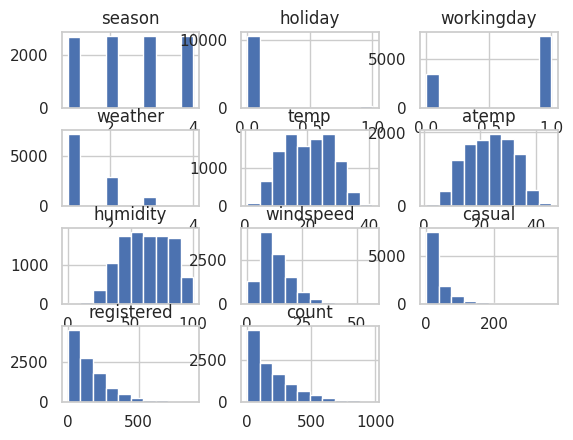

In [ ]:
df_train.hist()

In [ ]:
corr = df_train.corr(numeric_only=True)
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

#obs: caracteristicas categoricas son representadas de forma numerica pero no necesariamente tienen un ordenamiento (ej:estacion).
# debido a esto, en el caso de las categoricas, las correlaciones podrian no tener sentido.

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
season,1.000000,0.029368,-0.008126,0.008879,0.258689,0.264744,0.190610,-0.147121,0.096758,0.164011,0.163439
holiday,0.029368,1.000000,-0.250491,-0.007074,0.000295,-0.005215,0.001929,0.008409,0.043799,-0.020956,-0.005393
workingday,-0.008126,-0.250491,1.000000,0.033772,0.029966,0.024660,-0.010880,0.013373,-0.319111,0.119460,0.011594
weather,0.008879,-0.007074,0.033772,1.000000,-0.055035,-0.055376,0.406244,0.007261,-0.135918,-0.109340,-0.128655
temp,0.258689,0.000295,0.029966,-0.055035,1.000000,0.984948,-0.064949,-0.017852,0.467097,0.318571,0.394454
atemp,0.264744,-0.005215,0.024660,-0.055376,0.984948,1.000000,-0.043536,-0.057473,0.462067,0.314635,0.389784
humidity,0.190610,0.001929,-0.010880,0.406244,-0.064949,-0.043536,1.000000,-0.318607,-0.348187,-0.265458,-0.317371
windspeed,-0.147121,0.008409,0.013373,0.007261,-0.017852,-0.057473,-0.318607,1.000000,0.092276,0.091052,0.101369
casual,0.096758,0.043799,-0.319111,-0.135918,0.467097,0.462067,-0.348187,0.092276,1.000000,0.497250,0.690414
registered,0.164011,-0.020956,0.119460,-0.109340,0.318571,0.314635,-0.265458,0.091052,0.497250,1.000000,0.970948


**Relacion entre alquileres y tiempo meteorologico:**
Observando la matriz de correlacion vemos que las variables de temperatura y senacion termica tienen una alta correlacion con la cantidad de alquileres (variable count) respecto de las demas variables, presentando valores superiores a 0.38. Sin embargo, otras caracteristicas como la humedad, la velocidad del viento o las condiciones climaticas no parecen tener tanto peso a la hora de influenciar un aumento en la cantidad de alquileres. Si desgolsamos los alquileres en las clases casual y registered observamos que para los primeros la correlacion con la temperatura aumenta considerablemente, mientras para el caso de los usuarios registrado disminuye levemente. Esto puede indicar que los usuarios registrados utilizan el servicio de manera mas regular, mientras que los usuarios casuales podrian estar evaluando condiciones de temperatura agradables para utilizar el servicio.

**Utilizacion de codificaciones por defecto:**
En el contexto de este problema, se cuentan con varias variables categoricas (como por ejemplo season, weather, holiday y workingday) representadas de forma numerica. Esto puede presentar un problema si se utiliza un modelo como regresion lineal que evalua su rendimiento mendiante distancias. Por ejemplo, de la manera en la que esta codificado la caracteristica weather el modelo interpretaria que el valor 3 es tres veces mayor que el valor 1 que pueda tomar la caracteristica, lo cual en el contexto del problema no tiene sentido (condiciones climaticas no tienen un ordenamiento o importancia especifica respecto de las demas). Sin embargo, al utilizar arboles de decision, no se asumen dependencias lineales entre los valores de las caracteristicas y sus predicciones dependen de elegir un valor u otro (es una eleccion, no un calculo de cuanto tiene que valer esa caracteristica), haciendo que no sea necesaria ninguna transformacion en la codificacion de estas caracteristicas.

**Correlacion entre season y casual:**
En la matriz de correlacion se observa una correlacion leve entre ambas caracteristicas. A su vez vimos que casual tiene una muy alta correlacion con la temperatura. Uniendo ambos datos podriamos intepretar que el uso del servicio por parte de los usuarios aumenta de gran manera en las estaciones de mayor calor, es decir, primavera y verano. Sin embargo, el uso en invierno seria tan bajo en comparacion que compensaria el uso en verano, produciendo el efecto en la correlacion final entre la estacion y los alquileres de los usuarios casuales, reduciendo su valor final al considerar todas las estaciones del año.

## Parte 2 - Características temporales

La primera columna de los datos (*datetime*) corresponde a las marcas de tiempo asociadas a cada instancia. Para que estos tengan el orden cronológico que representan es necesario pasarlos de tipo *string* a tipo *datetime*. Para esto *Pandas* proporciona la función *to_datetime()*. Correr la siguiente celda para hacer el cambio.

In [ ]:
df_train['datetime'] = pd.to_datetime(df_train['datetime'])

##### La figura siguiente muestra cómo varía la cantidad de bicicletas alquiladas en función del tiempo.

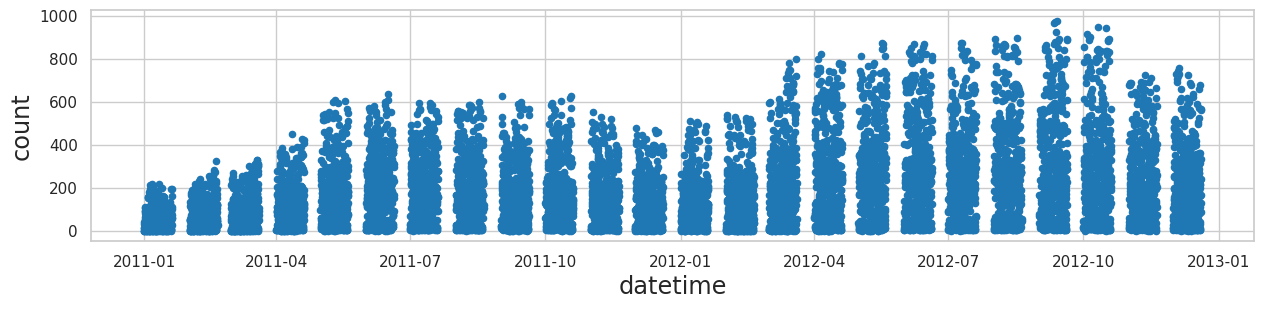

In [ ]:
df_train.plot(x='datetime', y='count', figsize=[15,3],kind='scatter',color='tab:blue')
plt.xlabel('datetime',fontsize='x-large')
plt.ylabel('count',fontsize='x-large')
plt.show()

#### Preguntas:

- ¿Le parece razonable la division en conjuntos de train y test que se tomó en el desafío?
- ¿Cómo varían temporalmente (día, semana, mes, año) los alquileres?

<p style="font-size:13px; color:#BB0000;">Respuesta a preguntas </p>

Idealmente, el conjunto de entrenamiento y test deberian representar de igual manera al conjunto de datos con el que estamos
trabajando,es decir, ambos conjuntos deberian tener la misma distribucion, representando lo mejor posible al conjunto de datos
completo. Sin embargo, el contexto del problema hace que los datos con los que se cuentan hagan referencia a dias de la semana,
horas del dia, etc, es decir, los datos con los que contamos hacen referencia a un ordenamiento temporal. Esto debe ser tomado en cuenta a la hora de realizar la particion de conjuntos ya que el entrenamiento no debe ser influenciado por datos del "futuro".

La idea de nuestro modelo es utilizar datos historicos sobre la demanda de alquileres y predecir como seran dichos alquileres en meses posteriores a los datos con los que contamos. Esta forma de predecir debe ser considerada a la hora de consturir dicho modelo ya que queremos "enseñarle" esa manera de intepretar los datos.

Es por lo anterior que tanto train como test deben tener una dependencia temporal entre si. Train debe ser utilizado para entrenar con datos del pasado y test se utilizara para evaluar el modelo entrenado en datos futuros dentro de un mismo mes (Ya que estaremos prediciendo demanda mensual). Si colocaramos datos en test con fecha anterior que los datos en train estariamos "enseñandole" al modelo a utilizar datos de dias futuros para predecir demanda pasada, lo cual en la practica es totalmente imposible de hacer, y por lo tanto estariamos influenciando un comportamiento incorrecto al modelo. A esto se le llama que el modelo tenga data leakage.

Por otro lado, ¿que sucede para los datos en train que son posteriores temporalmente debido a que pertenecen a un mes posterior? En este escenario podria argumentarse que existe data leakage entre cada mes. Sin embargo, la idea del modelo no es predecir el comportamiento de los alquileres a lo largo de una linea temporal compuesta por todos los datos, sino que queremos predecir demanda mensual. Ademas, el modelo a utilizar no intepretara los meses como si tuvieran una dependencia entre si, sino que simplemente identificara el valor que tiene la carateristica y en base a ella hara su prediccion, independientmente del valor que tengan los demas datos. La clave es que el modelo predice demanda mensual y cada mes tiene un comportamiento intriseco a si mismo.




Por otra parte, debido al histograma anterior, vemos un crecimiento en la demanda de bicicletas año a año. Al entrenar el modelo de la forma mencionada, este efecto se capuraria ya que el modelo observaria cada mes en particular en conjunto con la variable año, pudiendo cambiar su prediccion en base al valor de esta ultima variable y el mes, logrando que el modelo pueda capturar el efecto del crecimiento anual.






El tipo de dato *datetime* permite extraer de forma sencilla datos categóricos como la hora, el día de la semana, entre otros. La siguiente celda agrega a los datos de *train* estas nuevas características.

In [ ]:
df_train['hour'] = df_train['datetime'].dt.hour
df_train['weekday'] = df_train['datetime'].dt.weekday

#si el formato de la fecha es: 2026-03-27 15:30:00, entonces dt.hour devolvera directamente la hora asociada a dicha fecha. Weekday
#devolvera que es el dia numero 4 de la semana. Para que funcione es necesario pasar la fecha a string como se hizo en una de las
#lineas anteriores.

df_train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,hour,weekday
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,0,5
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,1,5
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2,5
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,3,5
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,4,5


In [ ]:
corr2 = df_train.corr(numeric_only=True)
corr2.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,hour,weekday
season,1.000000,0.029368,-0.008126,0.008879,0.258689,0.264744,0.190610,-0.147121,0.096758,0.164011,0.163439,-0.006546,-0.010553
holiday,0.029368,1.000000,-0.250491,-0.007074,0.000295,-0.005215,0.001929,0.008409,0.043799,-0.020956,-0.005393,-0.000354,-0.191832
workingday,-0.008126,-0.250491,1.000000,0.033772,0.029966,0.024660,-0.010880,0.013373,-0.319111,0.119460,0.011594,0.002780,-0.704267
weather,0.008879,-0.007074,0.033772,1.000000,-0.055035,-0.055376,0.406244,0.007261,-0.135918,-0.109340,-0.128655,-0.022740,-0.047692
temp,0.258689,0.000295,0.029966,-0.055035,1.000000,0.984948,-0.064949,-0.017852,0.467097,0.318571,0.394454,0.145430,-0.038466
atemp,0.264744,-0.005215,0.024660,-0.055376,0.984948,1.000000,-0.043536,-0.057473,0.462067,0.314635,0.389784,0.140343,-0.040235
humidity,0.190610,0.001929,-0.010880,0.406244,-0.064949,-0.043536,1.000000,-0.318607,-0.348187,-0.265458,-0.317371,-0.278011,-0.026507
windspeed,-0.147121,0.008409,0.013373,0.007261,-0.017852,-0.057473,-0.318607,1.000000,0.092276,0.091052,0.101369,0.146631,-0.024804
casual,0.096758,0.043799,-0.319111,-0.135918,0.467097,0.462067,-0.348187,0.092276,1.000000,0.497250,0.690414,0.302045,0.246959
registered,0.164011,-0.020956,0.119460,-0.109340,0.318571,0.314635,-0.265458,0.091052,0.497250,1.000000,0.970948,0.380540,-0.084427


**Obs:** La variable hour presenta una correlación relativamente alta con la demanda. Esto es esperable, ya que el uso de bicicletas sigue un patrón horario muy marcado con picos en horarios laborales.

Sin embargo, la representacion de esta variable tiene una característica importante: es cíclica. La hora 23 y la hora 0 son consecutivas desde el punto de vista temporal, pero su representación numérica las ubica en extremos opuestos. Esto implica que la correlación lineal no captura correctamente la relación entre la hora del día y la demanda.

Para modelar correctamente este comportamiento, la hora podría transformarse mediante una codificación cíclica utilizando funciones seno y coseno. Esta transformación preserva la periodicidad de la variable y facilita el aprendizaje de patrones horarios por parte del modelo.

Una consideración similar aplica a la variable weekday, que también es una caracteristica cíclica.

#### Ejercicio:

 - Grafique count, registered y casual en función de las horas y el día de la semana. ([*Sugerencia:*](https://seaborn.pydata.org/generated/seaborn.barplot.html) Ejemplos de la biblioteca *seaborn*)

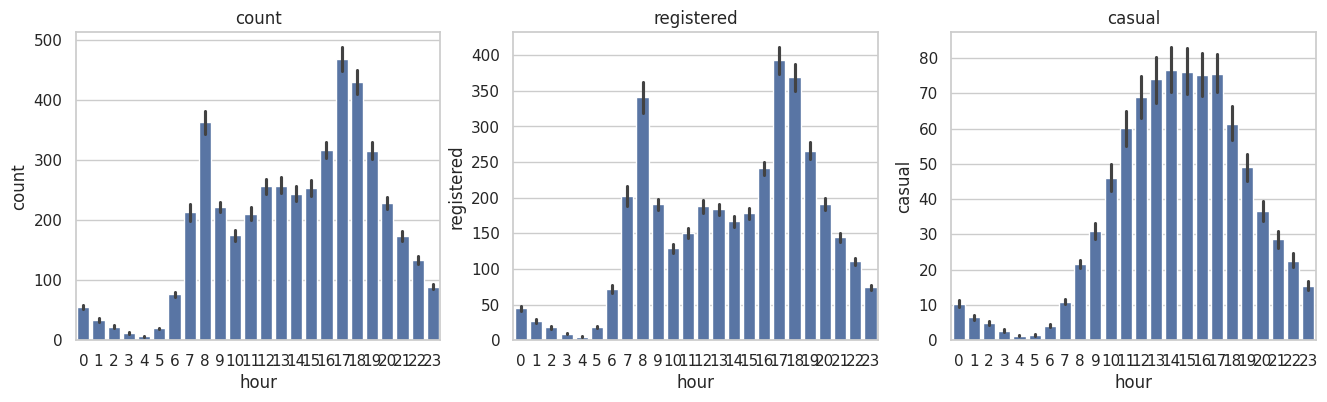

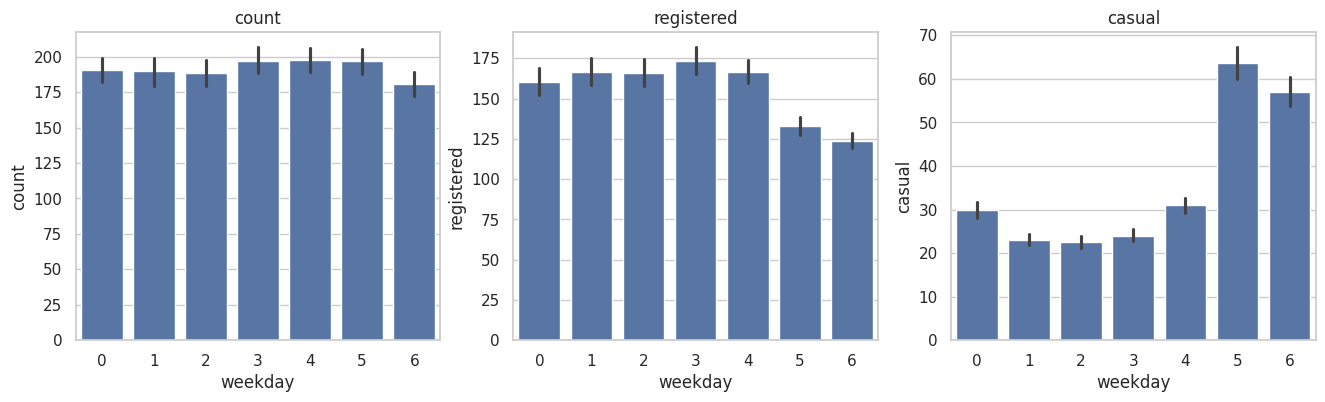

In [ ]:
plt.figure(figsize=(16,4))
plt.subplot(1,3,1)
sns.barplot(x='hour',y='count',data=df_train)
plt.title('count')
plt.subplot(1,3,2)
sns.barplot(x='hour',y='registered',data=df_train)
plt.title('registered')
plt.subplot(1,3,3)
sns.barplot(x='hour',y='casual',data=df_train)
plt.title('casual')
plt.show()

plt.figure(figsize=(16,4))
plt.subplot(1,3,1)
sns.barplot(x='weekday',y='count',data=df_train)
plt.title('count')
plt.subplot(1,3,2)
sns.barplot(x='weekday',y='registered',data=df_train)
plt.title('registered')
plt.subplot(1,3,3)
sns.barplot(x='weekday',y='casual',data=df_train)
plt.title('casual')
plt.show()

##### A partir de las gráficas responder las siguientes preguntas:

 - ¿Cómo explicaría la diferencia entre las distribuciones de los clientes registrados y casuales?
 - ¿Qué desventaja le encuentra a utilizar un regresor lineal para predecir los alquileres a partir de la hora del día?¿Cómo transformaría esta característica para paliar este problema?
 - ¿Es necesaria esta transformación cuando se utilizan Árboles de Decisión?

**Diferencias entre clientes registrados y casuales:**
En los histogramas anteriores, vemos como se divide el conjunto de alquileres totales segun el tipo de cliente que contrata el servicio. Registered representa la cantidad de alquileres de clientes que normalmente utilizan el servicio; casual seran los clientes que no se encuentran registrados en la base de datos del servicio como clientes regulares.

Los histogramas de ambos conjuntos muestran como el comportamiento de ambos tipos de clientes es fundamentalmente distinto entre si sin importar si se evalua la cantidad de alquileres segun las horas del dia o los dias de la semana. De dichos histogramas podriamos inferir que el cliente casual tiene a usar mas el servicio en momentos del dia donde es usual contar con tiempo libre (teniendo los valores maximos en torno a la hora 15). Por otro lado, los registrados en el servicio, utilizan el servicio en horarios distintos, pudiendo explicarse por un uso mas rutinario o de necesidad en ciertos horarios (ejemplo de esto seria el pico de las 8 horas).

Por otro lado, vemos el el conjunto casual tiende a usar mas el servicio los fines de semana, mientras que el uso de los registrados tiende a ser mas uniforme a lo largo de la semana, reforzando la idea explicada en el parrafo anterior.

**Desventajas de un regresor lineal:**
En primera instancia, un regresor lineal presenta el problema de, como dice su nombre, ser lineal. Si la demanda tuviera un comportamiento distinto al lineal, este seria un mal predictor. Sin embargo, esto puede solucionarse considerando alguna transformacion polinomica para conseguir un modelo que pueda adaptarse mejor a distintas funciones o comportamientos. Lamentablemente este no es el unico problema. Como se menciono anteriormente, considerar la caracteristica hora de la forma por defecto tiene los problemas que ya fueron mencionados. Ademas, como el regresor toma implicitamente un ordenamiento lineal de las caracteristicas que toma en cuenta, la hora 23 y 0 seran consideradas como lejanas, cuando no es asi, pudiendo producir comportamientos no deseados en la forma de predecir que el modelo realizara. Esto se podria solucionar realizando una transformacion ciclica de la variable como ya fue mencionado.

**Arboles de decision:** En los arboles de decision los problemas anteriores no existen ya que estos realizan elecciones logicas (y no basadas en distancias euclidianas) respecto de los valores y no asumen linealidad de los mismos. Pueden aprender relaciones segun intervalos de horas o valores especificos de las mismas y la cantidad de alquileres, captando patrones de picos o  valles segun las horas sin la necesidad de considerar a estas como lineales.

In [ ]:
df_train['month'] = df_train['datetime'].dt.month

#si el formato de la fecha es: 2026-03-27 15:30:00, entonces dt.hour devolvera directamente la hora asociada adicha fecha. Weekday
#devolvera que es el dia numero 4 de la semana. Para que funcione es necesario pasar la fecha a string como se hizo en una de las
#lineas anteriores.

df_train.head()


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,hour,weekday,month
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,0,5,1
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,1,5,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2,5,1
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,3,5,1
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,4,5,1


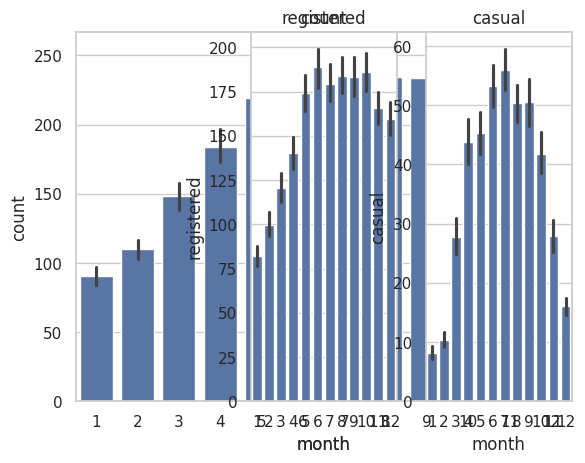

In [ ]:
sns.barplot(x='month',y='count',data=df_train)
plt.title('count')
plt.subplot(1,3,2)
sns.barplot(x='month',y='registered',data=df_train)
plt.title('registered')
plt.subplot(1,3,3)
sns.barplot(x='month',y='casual',data=df_train)
plt.title('casual')
plt.show()

#### Selección de Características:

*   Entre el día, el mes y el año ¿cuáles de estos datos les pareces agregar como nuevas características y cuáles no? y ¿Por qué?
*   Agregar las características seleccionadas.

Por lo argumentado anteriormente, tanto el año como el mes del año deben ser considerados como caracteristicas ya que agregan contexto sobre la fecha en la que se producen los alquileres. Ademas, agregarlas permite que el modelo pueda capturar tendencias de demanda que puedan tener meses especificos o años.

Por otro lado, para identificar los dias ya contamos con la variable weekday por lo que agegrar una variable que idenifique dias del mes no agregaria informacion adicional.

In [ ]:
df_train['year'] = df_train['datetime'].dt.year
df_train.head(20)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,hour,weekday,month,year
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16,0,5,1,2011
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40,1,5,1,2011
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32,2,5,1,2011
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13,3,5,1,2011
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1,4,5,1,2011
5,2011-01-01 05:00:00,1,0,0,2,9.84,12.880,75,6.0032,0,1,1,5,5,1,2011
6,2011-01-01 06:00:00,1,0,0,1,9.02,13.635,80,0.0000,2,0,2,6,5,1,2011
7,2011-01-01 07:00:00,1,0,0,1,8.20,12.880,86,0.0000,1,2,3,7,5,1,2011
8,2011-01-01 08:00:00,1,0,0,1,9.84,14.395,75,0.0000,1,7,8,8,5,1,2011
9,2011-01-01 09:00:00,1,0,0,1,13.12,17.425,76,0.0000,8,6,14,9,5,1,2011


## Parte 3 - Preparación de los datos y Métrica de evaluación

Previo a trabajar con los estimadores:

*   Apartar la columna objetivo y eliminarla del conjunto de entrenamiento.
*   Eliminar las columnas *'casual'* y *'registered'*. ¿Por qué esto es necesario?.
*   Eliminar la columna *'datetime'*.

Durante la actividad los estimadores deben ser evaluados con la misma medida de desempeño utilizada en la competencia:

Root Mean Squared Logarithmic Error (RMSLE)
$$\sqrt{\frac{1}{n}\sum_{i}^{n}\big(\log(y_{i} + 1) - \log(\hat{y}_{i} + 1)\big)^2}$$

Este tipo de medida se utiliza cuando los valores a estimar son grandes. La librería *Scikit-Learn* incluye la función de desempeño [*mean_squared_log_error*](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_log_error.html#sklearn.metrics.mean_squared_log_error) (MSLE), esta función se puede utilizar  para la validación ya que alcanza las mismas soluciones que su raíz (RMSLE). De igual forma los resultados se deben mostrar con RMSLE.  
También está disponible en versiones recientes (>=1.4) de *Scikit-Learn* la métrica [root_mean_squared_log_error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_log_error.html).

In [ ]:
y_train = df_train['count']
df_train.drop(['datetime', 'casual','registered','count'],axis=1,inplace=True)
#df_test = df_test.drop(['casual','registered','count', 'datetime'], axis=1
df_train.head(20)

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,hour,weekday,month,year
0,1,0,0,1,9.84,14.395,81,0.0000,0,5,1,2011
1,1,0,0,1,9.02,13.635,80,0.0000,1,5,1,2011
2,1,0,0,1,9.02,13.635,80,0.0000,2,5,1,2011
3,1,0,0,1,9.84,14.395,75,0.0000,3,5,1,2011
4,1,0,0,1,9.84,14.395,75,0.0000,4,5,1,2011
5,1,0,0,2,9.84,12.880,75,6.0032,5,5,1,2011
6,1,0,0,1,9.02,13.635,80,0.0000,6,5,1,2011
7,1,0,0,1,8.20,12.880,86,0.0000,7,5,1,2011
8,1,0,0,1,9.84,14.395,75,0.0000,8,5,1,2011
9,1,0,0,1,13.12,17.425,76,0.0000,9,5,1,2011


In [ ]:
y_train.head(20)

,count
0,16
1,40
2,32
3,13
4,1
5,1
6,2
7,3
8,8
9,14


In [ ]:
df_test['datetime'] = pd.to_datetime(df_test['datetime'])
#se pasa fecha a string para poder aplicar .dt y asi obtener horas, semanas, etc como columnas separadas.
df_test['hour'] = df_test['datetime'].dt.hour
df_test['weekday'] = df_test['datetime'].dt.weekday
df_test['month'] = df_test['datetime'].dt.month
df_test['year'] = df_test['datetime'].dt.year
df_test.head()



,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,hour,weekday,month,year
0,2011-01-20 00:00:00,1,0,1,1,10.66,11.365,56,26.0027,0,3,1,2011
1,2011-01-20 01:00:00,1,0,1,1,10.66,13.635,56,0.0000,1,3,1,2011
2,2011-01-20 02:00:00,1,0,1,1,10.66,13.635,56,0.0000,2,3,1,2011
3,2011-01-20 03:00:00,1,0,1,1,10.66,12.880,56,11.0014,3,3,1,2011
4,2011-01-20 04:00:00,1,0,1,1,10.66,12.880,56,11.0014,4,3,1,2011


In [ ]:
df_test = df_test.drop('datetime', axis=1)
df_test.head(20)

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,hour,weekday,month,year
0,1,0,1,1,10.66,11.365,56,26.0027,0,3,1,2011
1,1,0,1,1,10.66,13.635,56,0.0000,1,3,1,2011
2,1,0,1,1,10.66,13.635,56,0.0000,2,3,1,2011
3,1,0,1,1,10.66,12.880,56,11.0014,3,3,1,2011
4,1,0,1,1,10.66,12.880,56,11.0014,4,3,1,2011
5,1,0,1,1,9.84,11.365,60,15.0013,5,3,1,2011
6,1,0,1,1,9.02,10.605,60,15.0013,6,3,1,2011
7,1,0,1,1,9.02,10.605,55,15.0013,7,3,1,2011
8,1,0,1,1,9.02,10.605,55,19.0012,8,3,1,2011
9,1,0,1,2,9.84,11.365,52,15.0013,9,3,1,2011


## Parte 4 - Decision Trees

### TransformedTargetRegressor

Observando los valores de las etiquetas se puede ver que la distribución de estos tiene una asimetría a la derecha, por lo que se puede aplicar una transformación logarítmica para que la distribución de las etiquetas sea más normal.

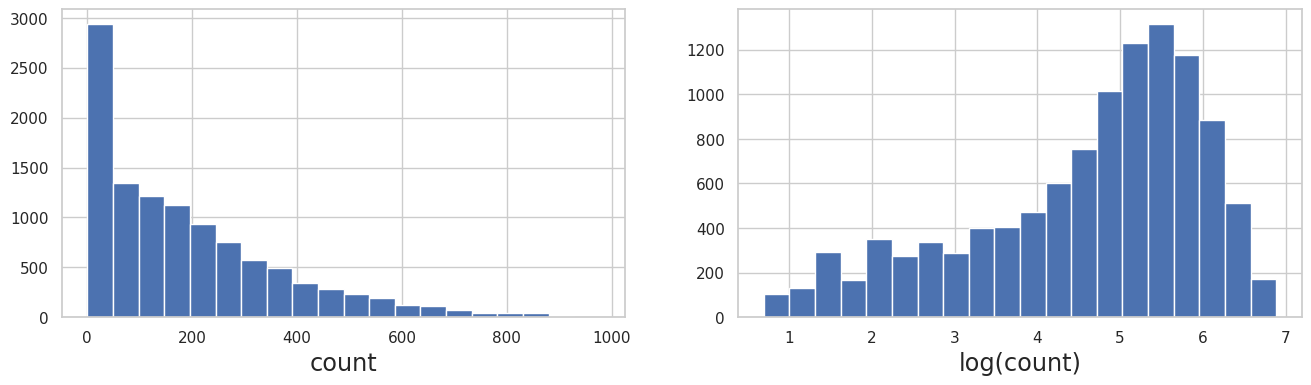

In [ ]:
plt.figure(figsize=(16,4))
plt.subplot(1,2,1)
y_train.hist(bins=20)
plt.xlabel('count',fontsize='x-large')
plt.subplot(1,2,2)
np.log1p(y_train).hist(bins=20)
plt.xlabel('log(count)',fontsize='x-large')
plt.show()

Si le pasamos al regresor estas etqiquetas tranformadas este predecirá el logaritmo de los alquileres, por lo que luego deberíamos calcular la exponencial del valor predicho. Por suerte, Scikit-Learn cuenta con la función [TransformedTargetRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html) que resuelve este problema.

**Nota: Consultar el Capítulo 2 del Libro del Curso por más información**

#### Objetivos

*   Importar la función *DecisionTreeRegressor()* de *Scikit-Learn* y utilizar *TransformedTargetRegressor* para tranformar logarítmicamente las etiquetas. Utilizar las funciones ***np.log1p*** y ***np.expm1*** para calcular el logaritmo y la exponencial respectivamente (ver ejemplo en ayuda de la función *TransformedTargetRegressor*).
*   Aplicar validación cruzada (10-Folds) a un estimador con los hiper-parámetros por defecto.
*   Graficar los valores de RMSLE de entrenamiento y validación. Calcular la media y la desviación estandar e incluir esta última en el gráfico. Para lo último utilizar la función *fill_between()* de *matplotlib*.

**Nota:** Puede pasarle ***random-state=2*** al estimador,*DecisionTreeRegressor()*,  para controlar la aleatoreidad del mismo. De no hacerlo puede que los resultados que obtenga difieran en cierta medida de los esperados.

In [ ]:
#Definicion del modelo: Arbol de decision.

from sklearn.compose import TransformedTargetRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import make_scorer, mean_squared_log_error

#Se define arbol de decision que aplicaremos
arbol = DecisionTreeRegressor()
#La funcion TransformedTargetRegressor aplica una transformacion a la variable a estimar, aplica el modelo y luego deshace la transformacion
#para obtener el valor correcto a estimar. Util cuando se aplican transformaciones no lineales.
modelo = TransformedTargetRegressor(regressor=arbol, func=np.log1p, inverse_func=np.expm1)
modelo.fit(df_train, y_train)
y_pred_train = modelo.predict(df_train)

In [ ]:
def rmsle(y_true, y_pred):
    return np.sqrt(mean_squared_log_error(y_true, y_pred))
rmsle_scorer = make_scorer(rmsle, greater_is_better=False)

In [ ]:
#Validacion Cruzada.
cv = KFold(n_splits=10, shuffle=True, random_state=2)

scores = cross_validate(
    modelo,
    df_train,
    y_train,
    cv=cv,
    scoring=rmsle_scorer,
    return_train_score=True
)


In [ ]:
#Dentro de la variable scores, se encuentran los resultados de los errores RMSLE obtenidos a la hora de entrenar y validar
#con los 10 folds de la validacion cruzada. A estos, podemos graficarlos u obtener estadisticas como la media y la varianza de
#estos errores.

train_scores = -scores['train_score']
val_scores   = -scores['test_score']

mean_rmsle_train = train_scores.mean()
std_rmsle_train  = train_scores.std()

mean_rmsle_val = val_scores.mean()
std_rmsle_val  = val_scores.std()

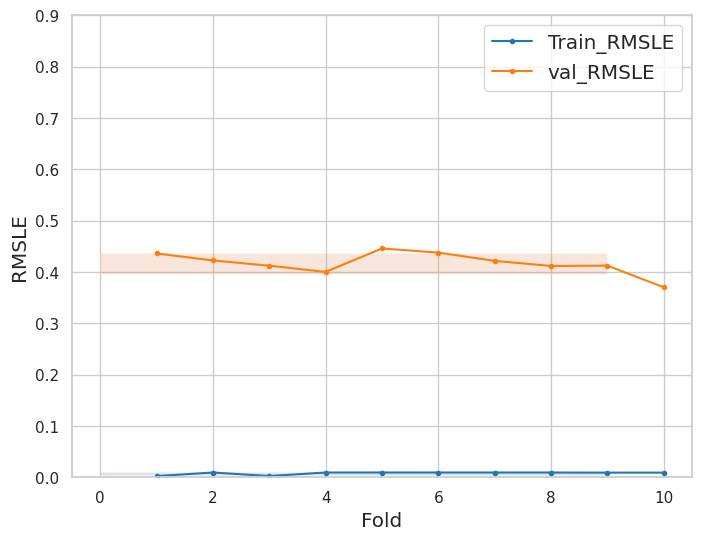

In [ ]:
### Ayuda de Gráfica
## Se crea la figura
x = np.arange(1,11)
plt.figure(figsize=(8,6))

## Se grafican los valores de RMSLE de entrenamiento y validación
plt.plot(x, train_scores,'.-',color='tab:blue',label='Train_RMSLE')
plt.plot(x, val_scores,'.-',color='tab:orange',label='val_RMSLE')



## Se grafica la media y desviación etándar
plt.fill_between(np.arange(10), mean_rmsle_train + std_rmsle_train, mean_rmsle_train - std_rmsle_train, alpha=0.2)
plt.fill_between(np.arange(10), mean_rmsle_val + std_rmsle_val, mean_rmsle_val - std_rmsle_val, alpha=0.2)

plt.xlabel('Fold',fontsize='large')
plt.ylabel('RMSLE',fontsize='large')
plt.legend(fontsize='large')
plt.ylim([0,0.9])
plt.show()

#### Preguntas:

*   ¿Qué fenómeno se logra apreciar en el gráfico? ¿A qué se debe? ¿Por qué esto es un problema?
*   Indicar y describir alguno de los hiper-parámetros que la función *DecisionTreeRegressor()* ofrece para limitar la complejidad del estimador.

**Observaciones sobre el modelo anterior:**
El arbol definido tiene parametros por defecto, es decir, puede crear ramas de forma ilimitada, entre otras propiedades. Es por esto que a la hora de entrenar el modelo, el arbol no tiene limitaciones a la hora de cuanta precision sobre el conjunto de entrenamiento debe tener. Esto trae complicaciones si los datos cuentan con ruido o con caracteristicas muy especificas ya que modelo se ajustara de manera excesiva a los datos de entrenamiento, impidiendo que el mismo generalice el comportamiento del problema.

Es por lo anterior que vemos que para los 10 folds, el error de validacion(error obtenido sobre los datos que quedaron afuera del entrenamiento para un fold especifico) es bastante mas alto que el error de entrenamiento, mostrando como el modelo contiene sobreajuste y no logra generalizar el comportamiento del problema.

Para solucionar esto debemos aplicar regularizacion al arbol de decision, es decir, limitar la complejidad del arbol resultante de alguna manera. Para ello contamos con varios parametros que podemos ajustar:

**Max_depth:** Indica la profundidad maxima que puede tener el arbol.

**Min_samples_leaf:** Cantidad minima de muestras que puede tener cada hoja.

**Min_samples_split:** Cantidad minima de muestras necesarias para realizar la division de un nodo.

**Max_leaf_nodes:** Numero que limita la cantidad de hojas del arbol.

#### Ejemplo Lack of smoothness

Como ejemplo se tomará la siguiente situación:

 - Domingo
 - Despejado o Parcialmente nublado
 - A las 19 horas
 - En primavera

Se observará el efecto de la temperatura en la predicción de alquileres de bicicletas.

 - ¿Cómo espera que sea dicho efecto en un rango de 10°C a 30°C?

La idea de las celdas inferiores es diseñar un dataframe puntual para experimentar como el modelo predice los alquileres cuando unicamente la caracteristica temperatura cambia en los distintos datos.
Para eso se toma un dato especifico de nuestro dataframe (en este caso se toma una entrada que corresponda con un domingo, despejado, a las 19 horas y en primavera). Luego, se lo duplica 21 veces para generar un data frame con la misma entrada 21 veces repetida.
Con lo anterior, se modifica la temperatura de estas variables de manera de tener 21 entradas coya unica diferencia sea la temperatura.
Con este data frame "artificial" se entrena el modelo y se grafica la prediccion que realiza en funcion de los valores de temperatura que se hayan colocado.
Esto se hace para observar el comportamiento del modelo y la influencia de una variable en la prediccion de los alquileres.

In [ ]:
index = 2685
Domingo = df_train.iloc[index:index+1]
Domingo

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,hour,weekday,month,year
2685,2,0,0,1,29.52,34.09,62,8.9981,19,6,6,2011


In [ ]:
## Se crea un dataframe con los datos del domingo
X_prueba = pd.concat([Domingo]*21,ignore_index=True)

index = 0
for k in np.linspace(10,30,21):
    X_prueba.loc[index,'temp']= k
    ## De igual manera se cambia la sensación térmica para mantener cierta coherencia
    X_prueba.loc[index,'atemp']= k
    index += 1

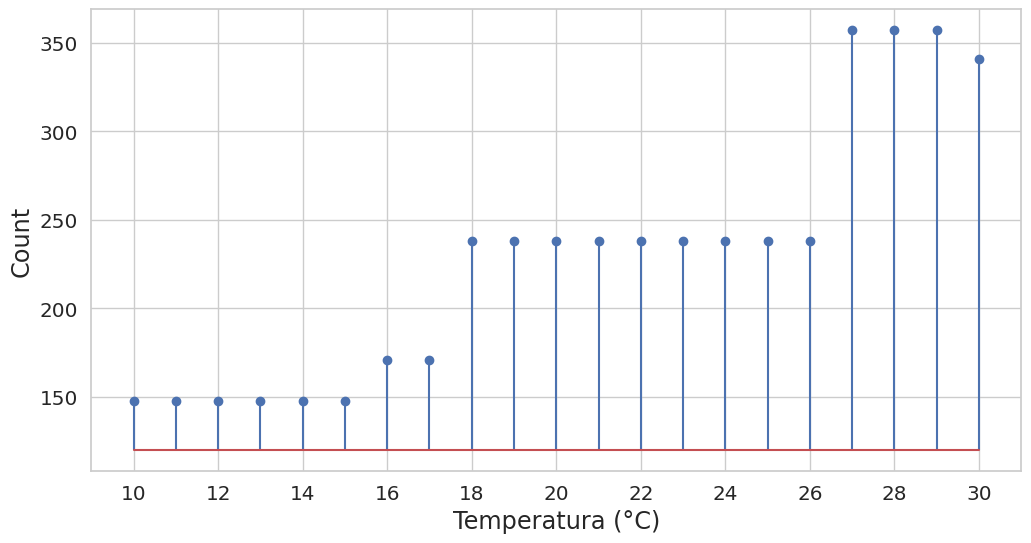

In [ ]:
#se grafican los valores predecidos restringiendonos a los dias domingo en funcion de la tempreratura

modelo.fit(df_train,y_train)

plt.figure(figsize=(12,6))
plt.stem(np.linspace(10,30,21),modelo.predict(X_prueba),bottom=120)
plt.xlabel('Temperatura (°C)',fontsize='x-large')
plt.ylabel('Count',fontsize='x-large')
plt.xticks(np.linspace(10,30,11),fontsize='large')
plt.yticks(fontsize='large')
plt.savefig('cambios_temp.png')
plt.show()

 - Observe el cambio que genera la temperatura a la salida (en particular el pasar de una temperatura de 23°C a 24°C, puede variar según la semilla, ver **Nota**).

 - ¿Qué desventaja le encuenta a los árboles de decisión en comparación con modelos lineales?

 **Nota:** Debido a la alta varianza de los Árboles de decisión los modelos obtenidos pueden variar de gran manera a efecto de pequeños cambios en el entrenamiento. En la carpeta se adjunta la imagen *cambios_temp.png* para que pueda discutir las preguntas a partir de la figura que se espera obtener.

Como fue mencionado antes, los arboles toman decisiones segun condiciones logicas, es decir, toman decisiones como por ejemplo:si temperatura ≤ 23.5 → usar hoja A sino usar hora B.
Esta forma de trabajar permite las ventajas que ya fueron mencionadas en las secciones anteriores, pero a su vez puede provocar el efecto del grafico anterior, haciendo que la prediccion varie bruzcamente al atravesar un "umbral" de temperatura. Por ejemplo, en el grafico esto se ve entre las temperaturas 15-16, 21-22 y 26-27, por lo tanto la propia utilizacion de los arboles implica obtener una prediccion que puede no ser lo suficientemente suave para representar correctamente el problema en temperaturas especificas.

### Ajuste Fino

#### Objetivos

*   Seleccionar uno de los hiper-parámetros y encontrar el mejor estimador.
*   Graficar los valores de RMSLE de entrenamiento y validación. Calcular la media y la desviación estandar e incluir esta última en el gráfico. Comparar con los resultados anteriores.
*   Graficar cómo varían los valores de RMSLE de entrenamiento y validación, para diferentes valores del hiper-parámetro.
*   Mostrar el mejor valor RMSLE (promedio de todos los *folds*) y el valor del hiper-parámetro.
*   Visualizar el árbol hasta los nodos de profundidad 2 utilizando la función *plot_tree()*. Agrandar el tamaño de la imagen de manera de poder leer la descripción de cada nodo.
*   Analizar las decisiones que está tomando el árbol para los primeros nodos.
*   Graficar los primeros 200 valores objetivo junto con sus predicciones.

**Nota:** Puede ser útil la función *save_gs_results()* que se encuentra en el archivo *comet_log.py* de la carpeta del taller para organizar sus experimentos con Comet.

In [ ]:
"""
train_means = []
train_stds  = []
val_means   = []
val_stds    = []

for d in depths:

    tree = DecisionTreeRegressor(max_depth=d, random_state=2)

    model = TransformedTargetRegressor(
        regressor=tree,
        func=np.log1p,
        inverse_func=np.expm1
    )

    scores = cross_validate(
        model, X, y,
        cv=10,
        scoring=rmsle_scorer,
        return_train_score=True
    )

    train_scores = -scores['train_score']
    val_scores   = -scores['test_score']

    train_means.append(train_scores.mean())
    train_stds.append(train_scores.std())
    val_means.append(val_scores.mean())
    val_stds.append(val_scores.std())
    """

"\ntrain_means = []\ntrain_stds  = []\nval_means   = []\nval_stds    = []\n\nfor d in depths:\n\n    tree = DecisionTreeRegressor(max_depth=d, random_state=2)\n\n    model = TransformedTargetRegressor(\n        regressor=tree,\n        func=np.log1p,\n        inverse_func=np.expm1\n    )\n\n    scores = cross_validate(\n        model, X, y,\n        cv=10,\n        scoring=rmsle_scorer,\n        return_train_score=True\n    )\n\n    train_scores = -scores['train_score']\n    val_scores   = -scores['test_score']\n\n    train_means.append(train_scores.mean())\n    train_stds.append(train_scores.std())\n    val_means.append(val_scores.mean())\n    val_stds.append(val_scores.std())\n    "

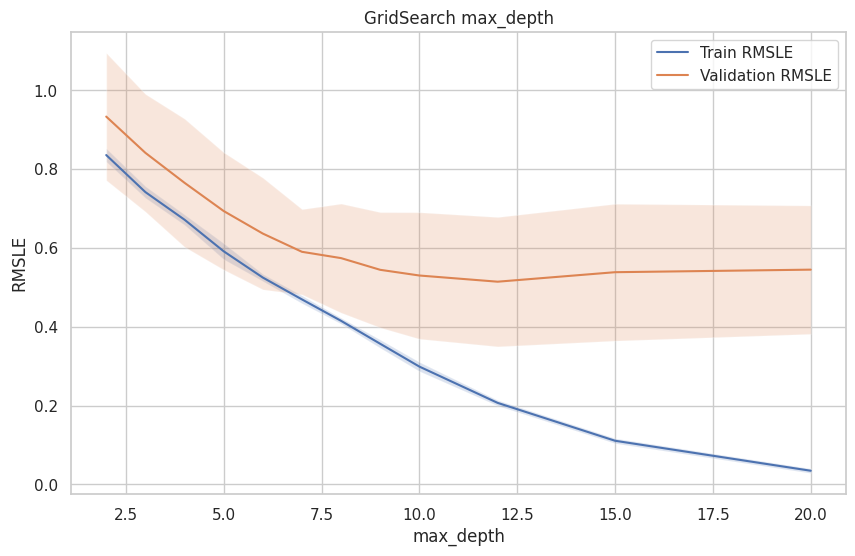

In [ ]:
from sklearn.model_selection import GridSearchCV
#GridSearchCV realiza un for utilizando como variable el parametro a optimizar en el modelo. Para cada uno de ellos se guarda
#el resultado de la media de los errores obtenidos para validacion cruzada con 10-folds. El modelo que tenga mejor error es el
#que se utilizara como modelo final.

# 1. Elegir uno de los hiper-parámetros, Por ejemplo max_depth

# 2. Definir la lista de valores a explorar

grilla = {
    "regressor__max_depth": [2,3,4,5,6,7,8,9,10,12,15,20]
}

# 3. Crear el regresor

arbol = DecisionTreeRegressor(random_state=2)

modelo = TransformedTargetRegressor(
    regressor=arbol,
    func=np.log1p,
    inverse_func=np.expm1
)


# 4. Crear el GridSearchCV

#
grid = GridSearchCV(
    modelo,
    grilla,
    cv=10,
    scoring=rmsle_scorer,
    return_train_score=True,
    n_jobs=-1
)

#Se ajustan todos los modelos a los datos.
grid.fit(df_train, y_train)


# 5. Realizar la búsqueda de hiper-parámetros

results = pd.DataFrame(grid.cv_results_)

depths = results["param_regressor__max_depth"].astype(int)

train_means = -results["mean_train_score"]
train_stds  = results["std_train_score"]

val_means = -results["mean_test_score"]
val_stds  = results["std_test_score"]


#Grafico de errores en funcion de los parametros explorados.

plt.figure(figsize=(10,6))

plt.plot(depths, train_means, label="Train RMSLE")
plt.plot(depths, val_means, label="Validation RMSLE")

plt.fill_between(depths,
                 train_means-train_stds,
                 train_means+train_stds,
                 alpha=0.2)

plt.fill_between(depths,
                 val_means-val_stds,
                 val_means+val_stds,
                 alpha=0.2)

plt.xlabel("max_depth")
plt.ylabel("RMSLE")
plt.legend()
plt.title("GridSearch max_depth")
plt.show()

In [ ]:
print("Best params:", grid.best_params_)
print("Best RMSLE:", -grid.best_score_)
print("Best estimator:", grid.best_estimator_)

Best params: {'regressor__max_depth': 12}
Best RMSLE: 0.5142262781038596
Best estimator: TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=DecisionTreeRegressor(max_depth=12,
                                                           random_state=2))


Al explorar todos los valores de profuncidad definidos se ve el comportamiento de la media de los errores de validacion y entrenamiento (RMSLE) a medida que se modifica este parametro.

A medida que aumenta max_depth, vemos como el modelo ajusta cada vez mejor los datos de entrenamiento, verificando el comportamiento que fue explicado anteriormente. Sin embargo, vemos que para max_depth = 12 obtenemos el menor error de validacion de entre todos los evaluados. A partir de este valor, el modelo pierde generalizacion y se ajusta de forma muy especifica a los datos, impidiendo que el modelo logre una buena prediccion para valores que no sean utilizados en el entrenamiento. Es por esto que el modelo a utilizar tendra que configurarse con max_depth = 12.

In [ ]:
# Quedarse con el mejor estimador encontrado

modelo_opt = grid.best_estimator_
modelo_opt.fit(df_train, y_train)


#Validacion Cruzada.




TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=DecisionTreeRegressor(max_depth=12,
                                                           random_state=2))

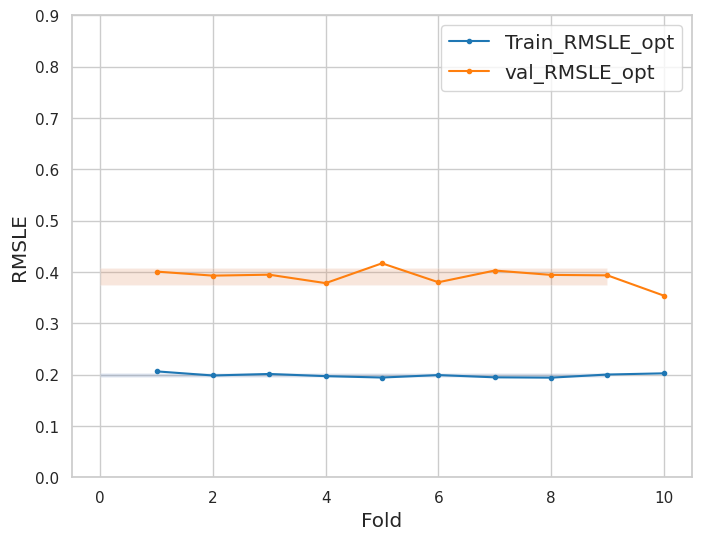

In [ ]:
# Evaluar el mejor estimador encontrado con validación cruzada

cv = KFold(n_splits=10, shuffle=True, random_state=2)

scores_opt = cross_validate(
    modelo_opt,
    df_train,
    y_train,
    cv=cv,
    scoring=rmsle_scorer,
    return_train_score=True
)

# Graficar los resultados de entrenamiento y validación para los folds
train_scores_opt = -scores_opt['train_score']
val_scores_opt   = -scores_opt['test_score']

mean_rmsle_train_opt = train_scores_opt.mean()
std_rmsle_train_opt  = train_scores_opt.std()

mean_rmsle_val_opt = val_scores_opt.mean()
std_rmsle_val_opt  = val_scores_opt.std()

### Ayuda de Gráfica
## Se crea la figura
x = np.arange(1,11)
plt.figure(figsize=(8,6))

## Se grafican los valores de RMSLE de entrenamiento y validación
plt.plot(x, train_scores_opt,'.-',color='tab:blue',label='Train_RMSLE_opt')
plt.plot(x, val_scores_opt,'.-',color='tab:orange',label='val_RMSLE_opt')



## Se grafica la media y desviación etándar
plt.fill_between(np.arange(10), mean_rmsle_train_opt + std_rmsle_train_opt, mean_rmsle_train_opt - std_rmsle_train_opt, alpha=0.2)
plt.fill_between(np.arange(10), mean_rmsle_val_opt + std_rmsle_val_opt, mean_rmsle_val_opt - std_rmsle_val_opt, alpha=0.2)

plt.xlabel('Fold',fontsize='large')
plt.ylabel('RMSLE',fontsize='large')
plt.legend(fontsize='large')
plt.ylim([0,0.9])
plt.show()

In [ ]:
# Explorar los resultados de GridSearchCV
# Suponiendo que el GridSearchCV se llama gs_tree
# gs_tree.cv_results_ es un diccionario con los resultados
# gs_tree.best_estimator_ es el mejor modelo encontrado
# gs_tree.best_params_ es el mejor conjunto de hiper-parámetros encontrado
# gs_tree.best_score_ es el mejor score obtenido en validación cruzada para el mejor modelo





In [ ]:
# Graficar los resultados de GridSearchCV
# Para cada valor de max_depth, graficar el resultado de entrenamiento y validación


In [ ]:
# Imprimir el mejor RMSLE obtenido y el mejor conjunto de hiper-parámetros


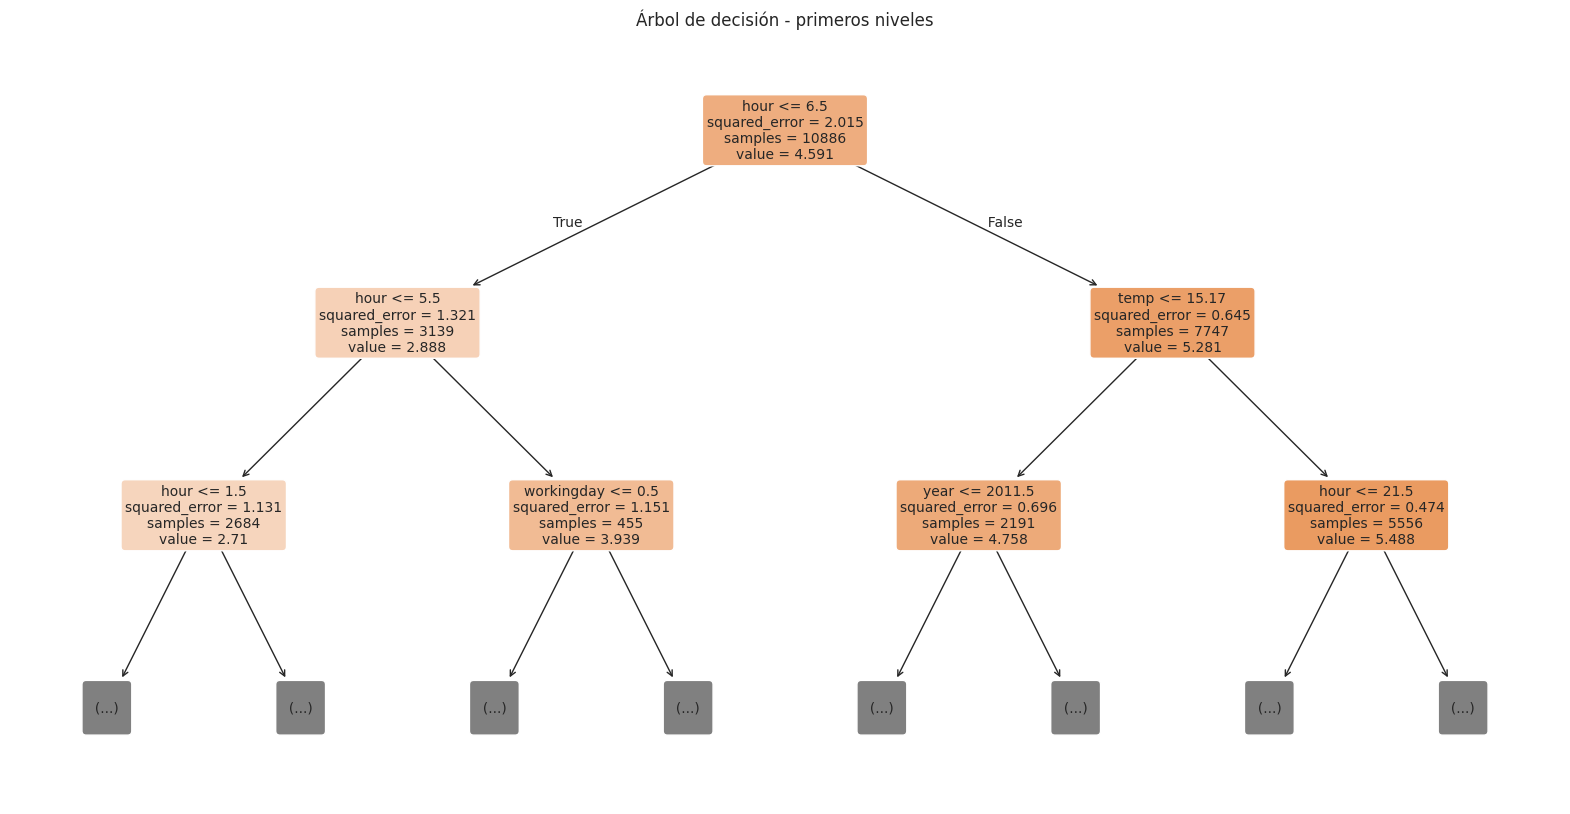

In [ ]:
# Mostrar el arbol de decisión del mejor modelo encontrado
# Usar plot_tree del módulo tree de sklearn
# mostrar solo las primeras 2 capas del árbol para que sea legible
from sklearn.tree import plot_tree

# mejor modelo encontrado por GridSearch (YA entrenado)
modelo_opt = grid.best_estimator_

# extraemos el árbol entrenado
arbol_final = modelo_opt.regressor_

plt.figure(figsize=(20,10))
plot_tree(
    arbol_final,
    feature_names=df_train.columns,
    max_depth=2,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Árbol de decisión - primeros niveles")
plt.show()

In [ ]:

# predecir sobre el conjunto de entrenamiento con el mejor modelo encontrado

y_pred_opt = modelo_opt.predict(df_train)

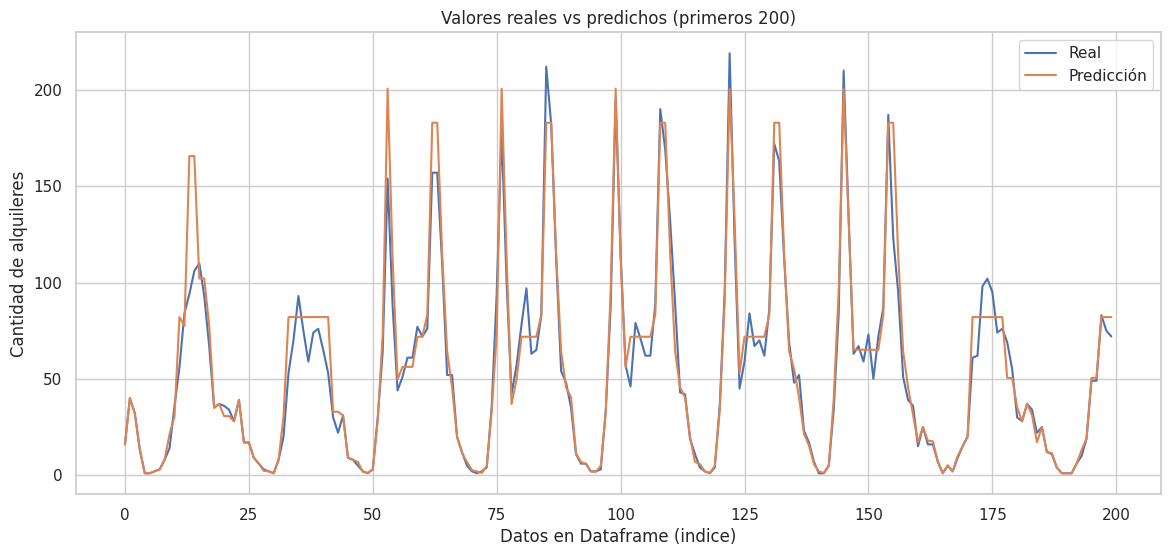

In [ ]:
# Graficar los primeros N valores reales y predichos para comparar
N = 200

plt.figure(figsize=(14,6))
plt.plot(y_train.values[:N], label="Real")
plt.plot(y_pred_opt[:N], label="Predicción")

plt.xlabel("Datos en Dataframe (indice)")
plt.ylabel("Cantidad de alquileres")
plt.title("Valores reales vs predichos (primeros 200)")
plt.legend()
plt.show()


Loguear a Comet y terminar el experimento

In [ ]:
# Iniciar el experimento a loguear en Comet
!pip install comet_ml
from comet_ml import Experiment

experiment = Experiment(
    api_key="EiUtNiy4RbtibndLjjwNX4GIb",
    project_name="bike-demand",
    workspace="santiago-marquez"
)


COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/santiago-marquez/bike-demand/afc0dc7b229643e78f60c509f76757e3



COMET INFO: Couldn't find a Git repository in '/content' nor in any parent directory. Set `COMET_GIT_DIRECTORY` if your Git Repository is elsewhere.


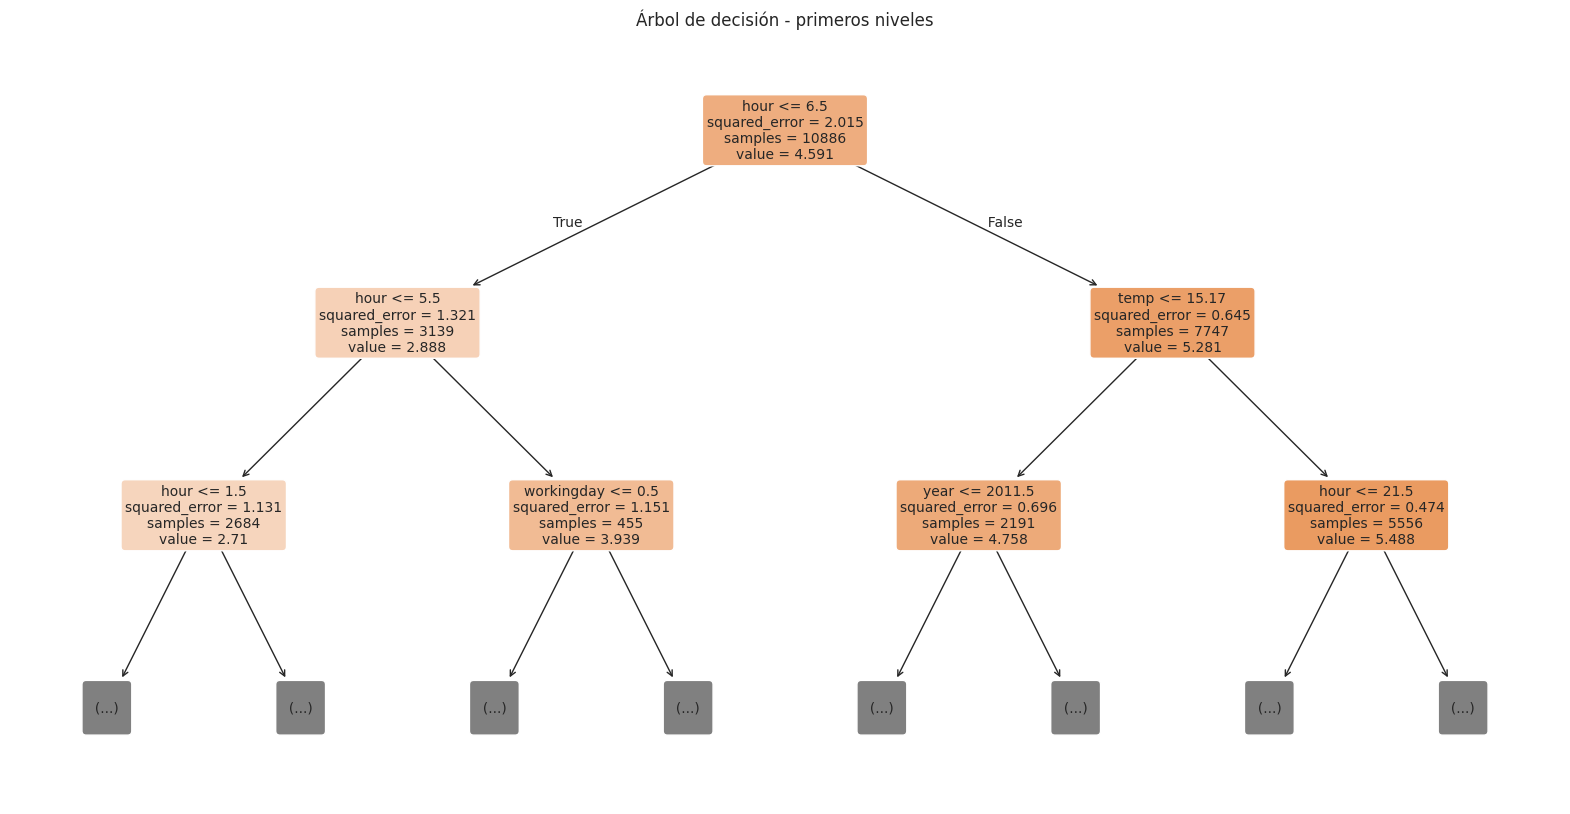

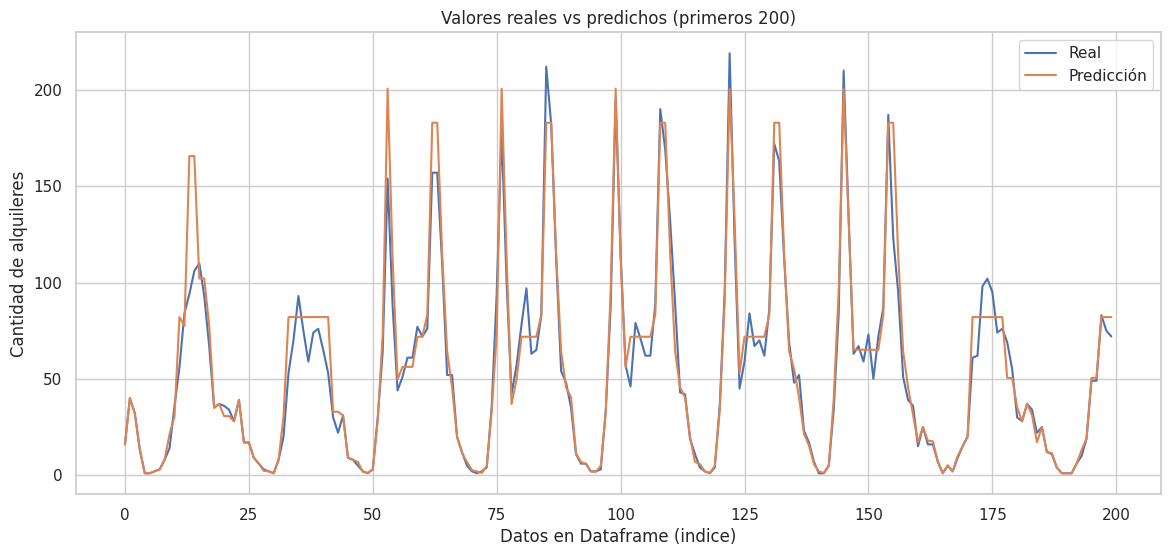

In [ ]:
# loguear resultados del grid search en Comet
best_depth = grid.best_params_["regressor__max_depth"]
experiment.log_parameter("best_depth", best_depth)

experiment.log_parameters(grid.best_params_)


#errores (validacion):

best_rmsle = -grid.best_score_
experiment.log_metric("RMSLE_cv", best_rmsle)

#arbol resultante

plt.figure(figsize=(20,10))
plot_tree(
    arbol_final,
    feature_names=df_train.columns,
    max_depth=2,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Árbol de decisión - primeros niveles")


experiment.log_figure("decision_tree_depth2", plt.gcf())

plt.show()

#prediccion vs datos reales

plt.figure(figsize=(14,6))
plt.plot(y_train.values[:N], label="Real")
plt.plot(y_pred_opt[:N], label="Predicción")

plt.xlabel("Datos en Dataframe (indice)")
plt.ylabel("Cantidad de alquileres")
plt.title("Valores reales vs predichos (primeros 200)")
plt.legend()

experiment.log_figure("pred_vs_real", plt.gcf())

plt.show()

In [ ]:
# terminar experimento en Comet

experiment.end()

COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------------------------------------------------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     name                  : prime_mastodon_5753
COMET INFO:     url                   : https://www.comet.com/santiago-marquez/bike-demand/afc0dc7b229643e78f60c509f76757e3
COMET INFO:   Metrics:
COMET INFO:     RMSLE_cv : 0.5142262781038596
COMET INFO:   Others:
COMET INFO:     notebook_url : https://colab.research.google.com/notebook#fileId=1a-wGs87YsiMT68Xnd5DHjNoOdRdV1lBn
COMET INFO:   Parameters:
COMET INFO:     best_depth           : 12
COMET INFO:     regressor__max_depth : 12
COMET INFO:   Uploads:
COMET INFO:     environment details : 1
COMET INFO:     figures             : 2
COMET INFO:     filename            : 1
COMET INFO:     installed packages  : 1
COMET INFO:    

## Parte 5 - Random Forest

#### Preguntas sobre métodos de Ensamble:

*   ¿Cuáles son las ventajes de los métodos de Ensamble?
*   ¿A qué métodos de ensamble está asociado *Random Forest*?.
*   Importar la función *RandomForestRegressor()* de *Scikit-Learn*.
*   Indicar y describir los principales hiper-parámetros de un *RandomForestRegressor()*.




Random Forest es un método de ensamble que combina múltiples árboles de decisión entrenados sobre subconjuntos aleatorios de datos y características, donde todos haran una prediccion y luego se tomara el promedio de las estimaciones realizadas por todos. Esta forma de integrar varios modelos permite mejorar la capacidad de generalizacion de la prediccion final. La intuicion sobre esto es que, si un arbol (con determinados parametros) es malo para predecir en cierto aspecto, existira otro que pueda predecir bien donde este falla, y al promediar se solucionan en gran manera la mayoria de errores de prediccion que puedan tener los arboles de forma individual.


Los hiperparámetros más importantes del modelo son:

**n_estimators:** cantidad de árboles del bosque.
**max_depth:** profundidad máxima de cada árbol.
**max_features:** número de características consideradas en cada división.
**min_samples_split / min_samples_leaf:** controlan el tamaño mínimo de nodos.
**bootstrap:** indica si se utiliza muestreo con reemplazo.


In [ ]:
from sklearn.ensemble import RandomForestRegressor

#### Ajuste fino



*   Encontrar el mejor estimador para *Random Forest* con la configuración por defecto.
*   Graficar los valores de RMSLE de entrenamiento y validación. Calcular la media y la desviación estándar e incluir esta última en el gráfico. Comparar con los resultados correspondientes de la parte 4.
*   Mostrar el mejor valor de RMSLE (promedio de todos los folds) y compararlo con el de la parte 4. Mostrar los valores seleccionados de los hiper-parámetros.
*   ¿Qué ventaja se pierde con repecto a usar un sólo árbol?
*   Graficar los primeros 200 valores objetivo junto con sus predicciones. Comparar con el gráfico correspondiente de la parte 4.
*   Mostrar la importancia de cada característica utilizando la variable *feature_importances_*.



RMSLE train mean: 0.1463596808368794
RMSLE val mean: 0.41713667276356103


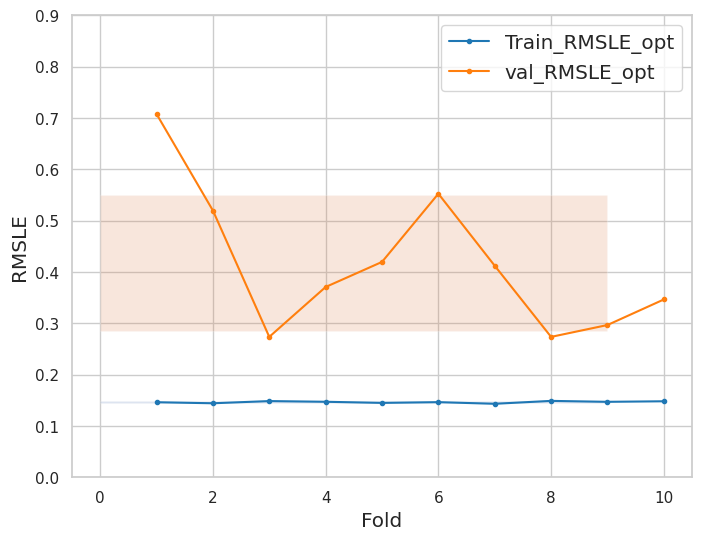

In [ ]:
forest = RandomForestRegressor(random_state=2)

scores_rf = cross_validate(
    forest,
    df_train,
    y_train,
    cv=10,
    scoring=rmsle_scorer,
    return_train_score=True,
    n_jobs=-1
)

train_scores_rf = -scores_rf["train_score"]
val_scores_rf   = -scores_rf["test_score"]

print("RMSLE train mean:", train_scores_rf.mean())
print("RMSLE val mean:", val_scores_rf.mean())


#Grafico

x = np.arange(1,11)
plt.figure(figsize=(8,6))

plt.plot(x, train_scores_rf,'.-',color='tab:blue',label='Train_RMSLE_opt')
plt.plot(x, val_scores_rf,'.-',color='tab:orange',label='val_RMSLE_opt')



## Se grafica la media y desviación etándar
plt.fill_between(np.arange(10), train_scores_rf.mean() + train_scores_rf.std(), train_scores_rf.mean() - train_scores_rf.std(), alpha=0.2)
plt.fill_between(np.arange(10), val_scores_rf.mean() + val_scores_rf.std(), val_scores_rf.mean() - val_scores_rf.std(), alpha=0.2)

plt.xlabel('Fold',fontsize='large')
plt.ylabel('RMSLE',fontsize='large')
plt.legend(fontsize='large')
plt.ylim([0,0.9])
plt.show()



**Obs: ** Aunque se observe un error de validacion mas variable al cambiar de fold en la validacion cruzada lo importante es observar cuando es el valor de este error en promedio. Haciendo eso vemos que el error de validacion es menor que al usar un unico arbol de decision, lo cual permite generalizar y obtener una prediccion mucho mas fiel a los datos reales (ver siguiente grafio). Como contra parte, se aumenta bastante el tiempo de ejecucion del modelo y por lo tanto el costo computacional de resolver el problema usando Random Forest.

{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 2, 'verbose': 0, 'warm_start': False}


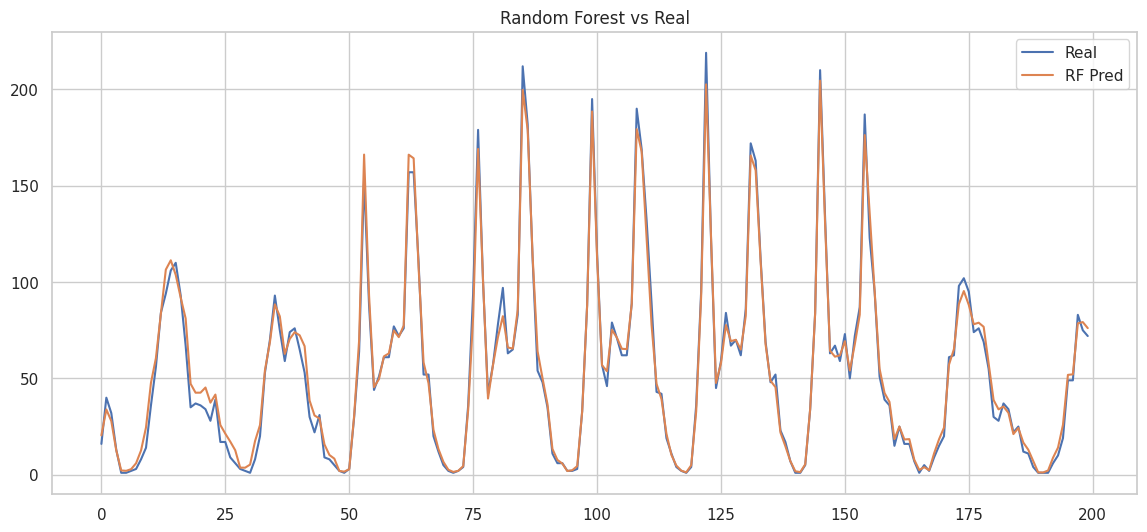

In [ ]:
forest.fit(df_train, y_train)
print(forest.get_params())

y_pred_rf = forest.predict(df_train)

plt.figure(figsize=(14,6))
plt.plot(y_train.values[:200], label="Real")
plt.plot(y_pred_rf[:200], label="RF Pred")

plt.title("Random Forest vs Real")
plt.legend()

experiment.log_figure("rf_pred_vs_real", plt.gcf())
plt.show()

## Parte 6 - Gradient Boosting

#### XGBoost

*   Indicar cuál es la principal diferencia entre *Bagging* y *Boosting*.
*   Importar la función *XGBRegressor()* de la librería [*xgboost*](https://github.com/dmlc/xgboost).
*   Este estimador a diferencia de los anteriores puede devolver predicciones negativas para estos datos. Indicar en que caso se pueda dar esto y por qué esto no sucedía con los estimadores anteriores.
*   Las predicciones negativas no pueden ser evaluadas por RMSLE. Por lo tanto, crear una nueva función de evaluación que fuerce a cero todos los valores negativos de las predicciones y luego calcule el valor de RMSLE. Para esto se debe utilizar la función *make_score* de *Sickit-Learn*, para que la nueva función pueda ser utilizada en las funciones de selección de modelos.


**Nota:** *Scikit-Learn* ofrece una implementación de *Gradient Boosting*, pero *XGBRegressor()* es la implementación de [*eXtreme Gradient Boosting*](https://arxiv.org/pdf/1603.02754.pdf?__hstc=133736337.1bb630f9cde2cb5f07430159d50a3c91.1513641600097.1513641600098.1513641600099.1&__hssc=133736337.1.1513641600100&__hsfp=528229161) un variante del algoritmo tradicional que dentro de algunas ventajas requiere menos tiempo de entrenamiento. La implementación de las funciones de la librería son muy similares a las de *Scikit-Learn*, de igual forma aquí le dejamos un [ejemplo](https://www.kaggle.com/alexisbcook/xgboost) de cómo usarla.







**Nota:** A partir de la versión **0.21** *Scikit-Learn* también ofrece una implementación de *Gradient Boosting* optimizada para data-sets grandes: [Histogram-based Gradient Boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html). Su funcionamiento se basa en agrupar en *bins* a los features de entrada, remplazandolos por integers. El número de *bins* es controlado por el hiperparámetro *max_bins*, el cual por defecto toma el valor 255 y no puede ser seteado a un valor mayor que este. En el Capítulo 7 del libro se encuentra más información acerca de este algoritmo.

**Diferencias entre Bagging y Boosting:**
Bagging entrena múltiples modelos de forma independiente y promedia sus predicciones para reducir la varianza. En cambio, Boosting entrena los modelos de forma secuencial, donde cada nuevo modelo intenta corregir los errores del anterior. Por esta razón, Boosting suele producir modelos más precisos pero más complejos.

**Implicacia de predicciones negativas:**
XGBoost puede generar predicciones negativas porque optimiza una función de pérdida sin restricciones sobre el rango de salida; cada arbol que forme parte del modelo sumara al valor final de la prediccion (los resultados de cada uno pueden ser tanto positivos como negativos). En los modelos anteriores esto no ocurría debido al uso de una transformación logarítmica sobre la variable objetivo, cuya transformación inversa garantiza valores positivos.

**Nuevo RMSLE:**
Dado que RMSLE no admite valores negativos, se definió una nueva función de evaluación que fuerza a cero las predicciones negativas antes de calcular la métrica. Esta función fue convertida a un scorer de Scikit-Learn mediante make_scorer para poder utilizarla en validación cruzada y búsqueda de hiperparámetros.

In [ ]:
!pip install xgboost
from xgboost import XGBRegressor

In [ ]:

def rmsle_clip(y_true, y_pred):
    y_pred = np.maximum(0, y_pred)   # 🔥 clave
    return np.sqrt(mean_squared_log_error(y_true, y_pred))

In [ ]:
from sklearn.metrics import make_scorer

rmsle_xgb = make_scorer(
    rmsle_clip,
    greater_is_better=False
)

#### Ajuste fino



*   Encontrar el mejor estimador para *Gradient Boosting* con la configuración por defecto.
*   Graficar los valores de RMSLE de entrenamiento y validación. Calcular la media y la desviación estandar e incluir esta última en el gráfico. Comparar con los gráficos correspondientes.
*   Mostrar el mejor valor de RMSLE (promedio de todos los folds) y compararlo con los anteriores. Mostrar los valores seleccionados de los hiper-parámetros.
*   Graficar los primeros 200 valores objetivo junto con sus predicciones. Comparar con los gráficos corespondientes.
*   ¿Qué compromiso hay entre los hiper-parámetros *n_estimators* y *learning_rate*?



In [ ]:
xgb = XGBRegressor(
    random_state=2,
    n_jobs=-1
)

scores_xgb = cross_validate(
    xgb,
    df_train,
    y_train,
    cv=10,
    scoring=rmsle_xgb,
    return_train_score=True,
    n_jobs=-1
)

train_scores_xgb = -scores_xgb["train_score"]
val_scores_xgb   = -scores_xgb["test_score"]

print("RMSLE train mean:", train_scores_xgb.mean())
print("RMSLE val mean:", val_scores_xgb.mean())

RMSLE train mean: 0.3653113461751356
RMSLE val mean: 0.6128599915551434


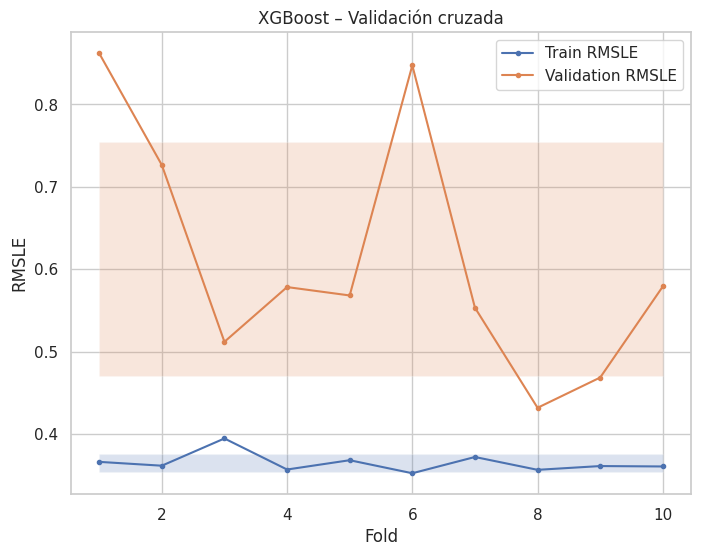

In [ ]:
x = np.arange(1,11)

plt.figure(figsize=(8,6))
plt.plot(x, train_scores_xgb,'.-',label='Train RMSLE')
plt.plot(x, val_scores_xgb,'.-',label='Validation RMSLE')

plt.fill_between(x,
                 train_scores_xgb.mean()-train_scores_xgb.std(),
                 train_scores_xgb.mean()+train_scores_xgb.std(),
                 alpha=0.2)

plt.fill_between(x,
                 val_scores_xgb.mean()-val_scores_xgb.std(),
                 val_scores_xgb.mean()+val_scores_xgb.std(),
                 alpha=0.2)

plt.xlabel('Fold')
plt.ylabel('RMSLE')
plt.legend()
plt.title("XGBoost – Validación cruzada")
plt.show()

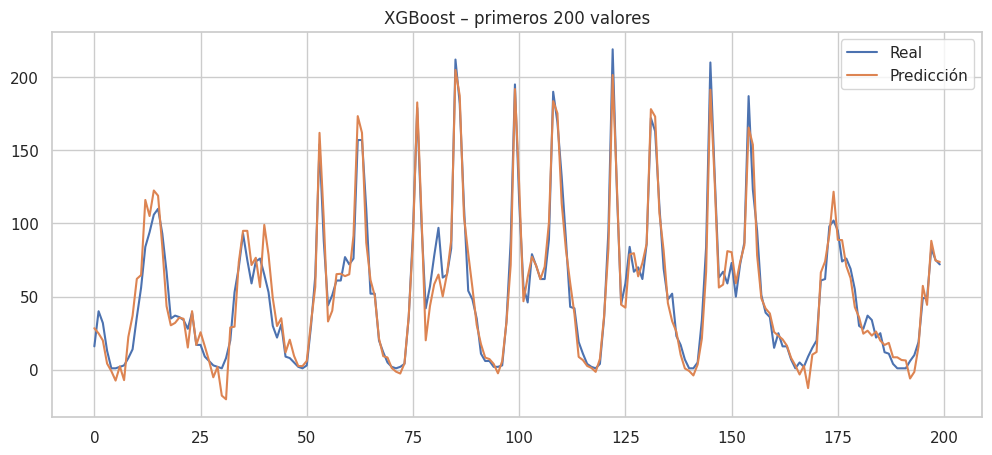

In [ ]:
xgb.fit(df_train, y_train)

y_pred_xgb = xgb.predict(df_train)

N = 200
plt.figure(figsize=(12,5))
plt.plot(y_train[:N].values, label="Real")
plt.plot(y_pred_xgb[:N], label="Predicción")
plt.legend()
plt.title("XGBoost – primeros 200 valores")
plt.show()

**XGBoost vs Random Forest:**
El modelo XGBoost con hiperparámetros por defecto obtuvo un RMSLE de validación peor que Random Forest, lo cual es esperable ya que XGBoost es un modelo más sensible a la elección de hiperparámetros, especialmente al learning rate y al número de estimadores. Random Forest, en cambio, suele ofrecer un buen desempeño sin necesidad de ajuste fino.

**Compormiso learning rate y cantidad de estimadores:**
Existe un compromiso entre learning_rate y n_estimators. Un learning rate alto hace que cada árbol tenga mayor impacto y se necesiten menos árboles, pero aumenta el riesgo de overfitting. En cambio, un learning rate bajo requiere un mayor número de árboles, pero permite un aprendizaje más gradual y generalmente mejora la capacidad de generalización del modelo.

## Parte 7 - Custom Transformers

- Construir un *Custom Transformer* que extraiga las caracterísicas temporales, siguiendo el ejemplo del capítulo 2 del libro.

In [ ]:
#Se crea transformer para aplicar ingenieria de caracteristicas de forma automatica.

from sklearn.base import BaseEstimator, TransformerMixin

#Se define el transformer como una subclase de BaseEstimator y TransformerMixin para tener funciones de estas dos clases.
#Ejemplos de esto: get_params(), set_params(), fit_transform().
class DateTimeFeaturesExtractor(BaseEstimator, TransformerMixin):

    def __init__(self, drop_original=True):
        self.drop_original = drop_original

    def fit(self, X, y=None):
        # En este caso no se necesita predecir nada. Solamente se crean caracteristicas con transform.
        return self

    def transform(self, X):
        X = X.copy()

        # Asegurarse que datetime sea string
        X["datetime"] = pd.to_datetime(X["datetime"])

        # Features temporales
        X["year"] = X["datetime"].dt.year
        X["month"] = X["datetime"].dt.month
        X["hour"] = X["datetime"].dt.hour
        X["weekday"] = X["datetime"].dt.weekday

        # Se agrega feature para indicar si es fin de semana
        X["is_weekend"] = (X["weekday"] >= 5).astype(int)

        # eliminar datetime original
        if self.drop_original:
            X = X.drop(columns=["datetime"])

        return X


## Parte 8 - Generar un modelo

#### Objetivos:

 - Generar el mejor modelo posible. Se podrá explorar posibles mejoras en cualquiera de las siguientes etapas:

    - Parámetros óptimos del regresor.
    - Predicción de alquileres registered y casual por separado.
    - Separación de conjunto de Entrenamiento y Validación tomando en cuenta la generación del conjunto de Test del desafío.
    - Cambios en las características utilizadas. (Agregando o quitando alguna de ellas)

In [ ]:
#Se reinician variables ya que en df_train quedaron todas las modificaciones que hicimos en las secciones anteriores.
#Queremos descargarlos de nuevo para verificar el comportamiento del pipline diseñado desde cero. Hay que sobre escribir cuando
#se descomprima el zip.
!kaggle competitions download -c bike-sharing-demand

bike-sharing-demand.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!unzip bike-sharing-demand.zip

Archive:  bike-sharing-demand.zip
replace sampleSubmission.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: yes
  inflating: sampleSubmission.csv    
replace test.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: yes
  inflating: test.csv                
replace train.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: yes
  inflating: train.csv               


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

modelo_final = Pipeline([
    ("datetime_features", DateTimeFeaturesExtractor()),
    ("forest",RandomForestRegressor(random_state=2))
])

#Se generan dos modelos para entrenar las dos variables.
modelo_casual = clone(modelo_final)
modelo_registered = clone(modelo_final)

#grilla de parametros:
param_grid = {
    "forest__n_estimators": [200, 400],
    "forest__max_depth": [10, 15, 20, None],
    "forest__min_samples_leaf": [1, 5, 10],
}

#lectura de datos y separacion de columna objetivo
df_train_full = pd.read_csv("train.csv")
# Targets separados
y_casual = df_train_full["casual"]
y_registered = df_train_full["registered"]

#Se eliminan columnas que queremos predecir
X = df_train_full.drop(columns=["count","casual","registered"])

#gridSearchCV para ajustar parametros del modelo usado en el pipeline
from sklearn.model_selection import GridSearchCV

grid_casual = GridSearchCV(
    modelo_final,
    param_grid,
    cv=10,
    scoring=rmsle_scorer,
    n_jobs=-1,
    verbose=1
)

grid_registered = GridSearchCV(
    modelo_final,
    param_grid,
    cv=10,
    scoring=rmsle_scorer,
    n_jobs=-1,
    verbose=1
)

#Se ejecuta el gridSearch para los datos. Aqui es donde se calculan los hiperparametros de todos los modelos
#considerados en el gridsearch. Tambien es donde se calcula la validacion cruzada para todos los modelos.
grid_casual.fit(X, y_casual)

grid_registered.fit(X, y_registered)

#prediccion de casual y registered
#modelo_casual.fit(X, y_casual)

#modelo_registered.fit(X, y_registered)

#Alquileres totales predecidos

modelo_casual = grid_casual.best_estimator_
modelo_registered = grid_registered.best_estimator_
pred_total = modelo_casual.predict(X) + modelo_registered.predict(X)

Fitting 10 folds for each of 24 candidates, totalling 240 fits
Fitting 10 folds for each of 24 candidates, totalling 240 fits


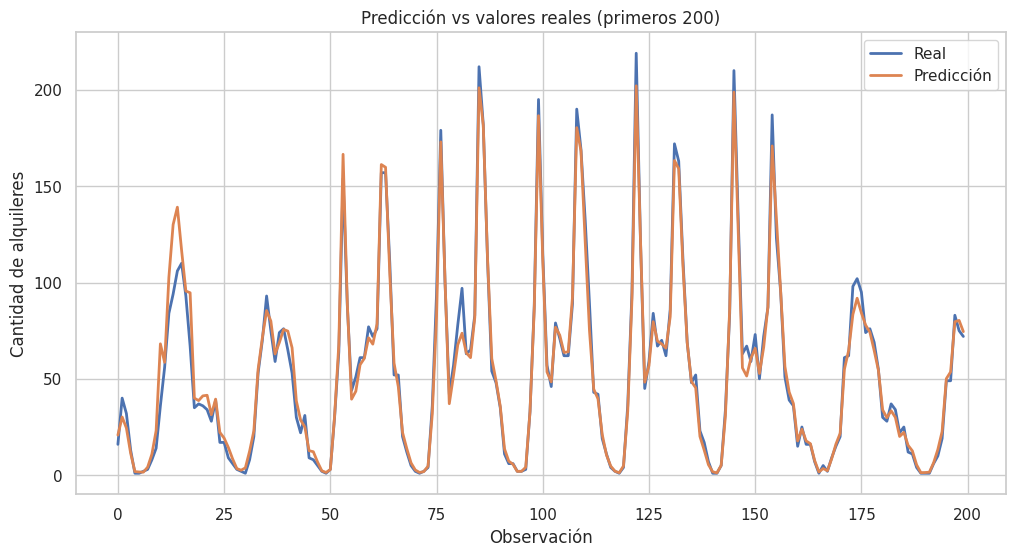

In [ ]:
# Valores reales del total
y_real_total = df_train_full["count"]

# Elegimos cuantos puntos mostrar
N = 200

plt.figure(figsize=(12,6))

plt.plot(y_real_total[:N].values, label="Real", linewidth=2)
plt.plot(pred_total[:N], label="Predicción", linewidth=2)

plt.xlabel("Observación")
plt.ylabel("Cantidad de alquileres")
plt.title("Predicción vs valores reales (primeros 200)")
plt.legend()
plt.grid(True)

plt.show()

**Codigo anterior:**
1) La primera mejora radica en el hecho de predecir los alquileres de usuarios casuales y registrados de forma separada. La logica de esto es que, al predecir unicamente la variable count se esta intentando englobar el comportamiento de dos problemas distintos (el comportamiento de los usuarios varia segun si son casuales o registrados como se vio al inicio del taller) en una sola variable. Al separar y entrenar dos modelos, se predice el comportamiento de ambos tipos de personas con mayor exactitud y por lo tanto, a la hora de sumar ambos y obtener el valor final de count, la prediccion sera mucho mas fiel de esta manera.

2) El modelo elegido es un Random Forest ya que fue el que mejor resultados nos dio en las secciones anteriores del taller. Tanto para casual como registered se realiza un gridSearch para buscar los parametros optimos del modelo.

3) Otras posibles mejoras involucrarian modificar o incluir caracteristicas adicionales. Por ejemplo, alguna caracteristica que contenga la demanda acumulada las ultimas 24 horas para cada dato del dataframe, fechas con codificacion ciclicas para agregar contexto a cada variable, entre otras.

## Parte 9 - Submit
Construir un *pipeline* para el estimador que considere que tuvo mejor desempeño. El pre-procesamiento debe incluir la extracción de las nuevas características, si corresponde.

Subir los resultados del *pipeline* para los datos de *test*,  a la [página](https://www.kaggle.com/c/bike-sharing-demand/submissions) de la competencia.

In [ ]:
df_test = pd.read_csv("test.csv")

X_test = df_test.copy()

#Se predicen los alquieres usando los datos del conjunto test
pred_casual = modelo_casual.predict(X_test)
pred_registered = modelo_registered.predict(X_test)

pred_total = pred_casual + pred_registered


submission = pd.DataFrame({
    "datetime": df_test["datetime"],
    "count": pred_total
})

submission.to_csv("submission.csv", index=False)

files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



*   ¿Cuánto fue el valor de RMSLE para el conjunto de test?


El score final obtenido fue de:

Private score: 0.46522

Public score: 0.46522